In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("retail_sales.csv", encoding='latin-1')

In [3]:
# 1. First 5 rows
print("First 5 Rows:")
print(df.head())

First 5 Rows:
         date store_id item_id  sales  price  promo  weekday  month
0  2019-01-01  store_1  item_1   41.0  21.30    0.0      1.0    1.0
1  2019-01-02  store_1  item_1   53.0  21.30    0.0      2.0    1.0
2  2019-01-03  store_1  item_1   39.0  21.30    0.0      3.0    1.0
3  2019-01-04  store_1  item_1   35.0  21.30    0.0      4.0    1.0
4  2019-01-05  store_1  item_1   51.0  17.04    1.0      5.0    1.0


In [4]:
# 2. Last 5 rows
print("\nLast 5 Rows:")
print(df.tail())


Last 5 Rows:
               date  store_id  item_id  sales  price  promo  weekday  month
1583092  2023-11-12  store_18  item_17   20.0  78.34    1.0      6.0   11.0
1583093  2023-11-13  store_18  item_17   17.0  97.93    0.0      0.0   11.0
1583094  2023-11-14  store_18  item_17   14.0  97.93    0.0      1.0   11.0
1583095  2023-11-15  store_18  item_17   19.0  97.93    0.0      2.0   11.0
1583096          20       NaN      NaN    NaN    NaN    NaN      NaN    NaN


In [5]:
# 4. Column names
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['date', 'store_id', 'item_id', 'sales', 'price', 'promo', 'weekday', 'month']


In [6]:
# 5. Data types
print("\nData Types:")
print(df.dtypes)


Data Types:
date         object
store_id     object
item_id      object
sales       float64
price       float64
promo       float64
weekday     float64
month       float64
dtype: object


In [7]:
# 6. Dataset information
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1583097 entries, 0 to 1583096
Data columns (total 8 columns):
 #   Column    Non-Null Count    Dtype  
---  ------    --------------    -----  
 0   date      1583097 non-null  object 
 1   store_id  1583096 non-null  object 
 2   item_id   1583096 non-null  object 
 3   sales     1583096 non-null  float64
 4   price     1583096 non-null  float64
 5   promo     1583096 non-null  float64
 6   weekday   1583096 non-null  float64
 7   month     1583096 non-null  float64
dtypes: float64(5), object(3)
memory usage: 96.6+ MB


In [8]:
# 8. Duplicate records
print("\nNumber of Duplicate Records:")
print(df.duplicated().sum())


Number of Duplicate Records:
0


2. Exploratory Data Analysis (EDA)

In [9]:
# Numerical variables
numerical_variables = df.select_dtypes(include=np.number).columns

print("Numerical Variables:")
print(numerical_variables.tolist())

# Categorical variables
categorical_variables = df.select_dtypes(exclude=np.number).columns

print("\nCategorical Variables:")
print(categorical_variables.tolist())

Numerical Variables:
['sales', 'price', 'promo', 'weekday', 'month']

Categorical Variables:
['date', 'store_id', 'item_id']


B. Distribution Plots

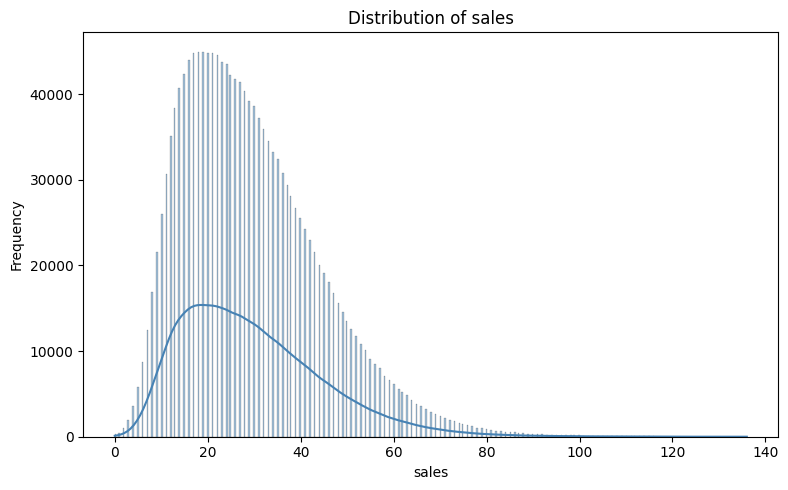

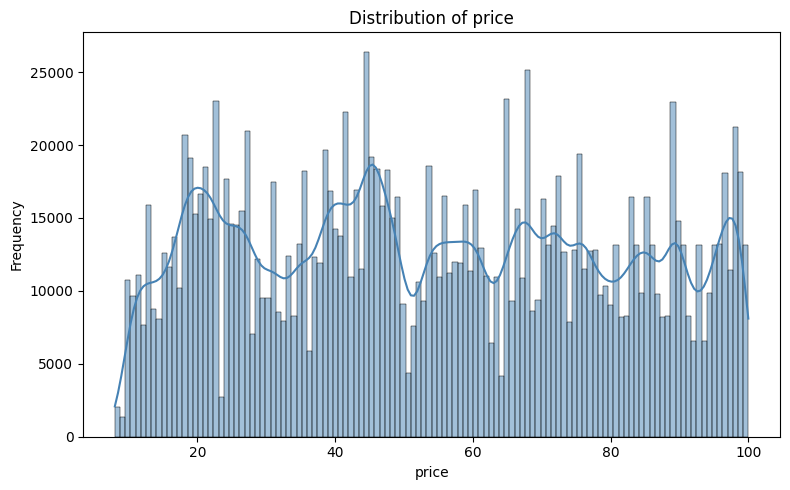

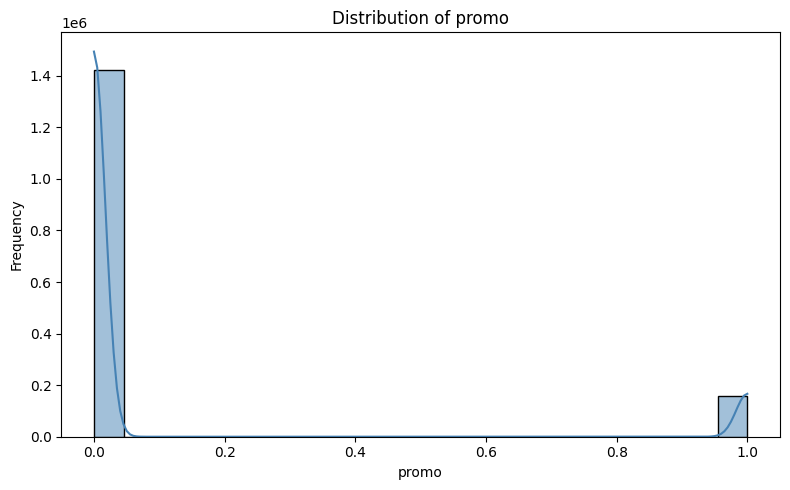

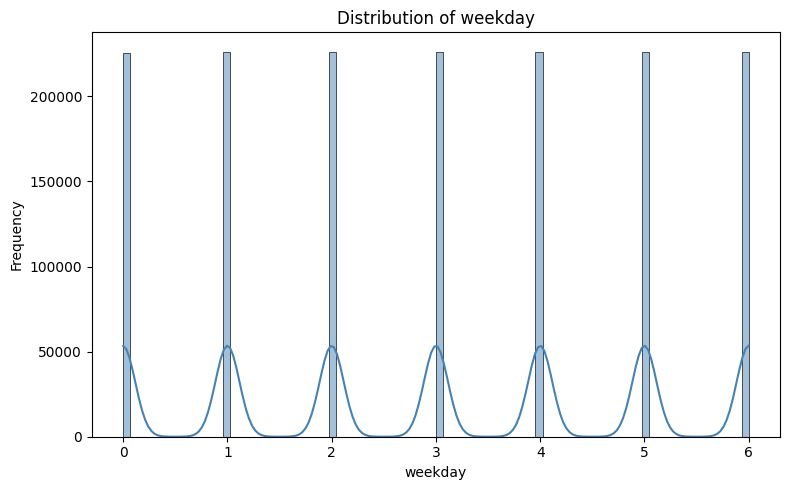

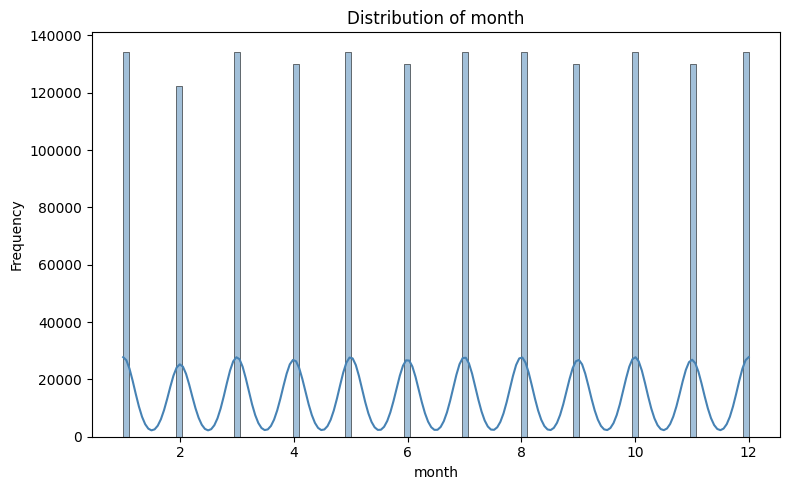

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

for column in numerical_variables:
    plt.figure(figsize=(8, 5))

    sns.histplot(
        df[column].dropna(),
        kde=True,
        color='steelblue'
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


C. Box Plots

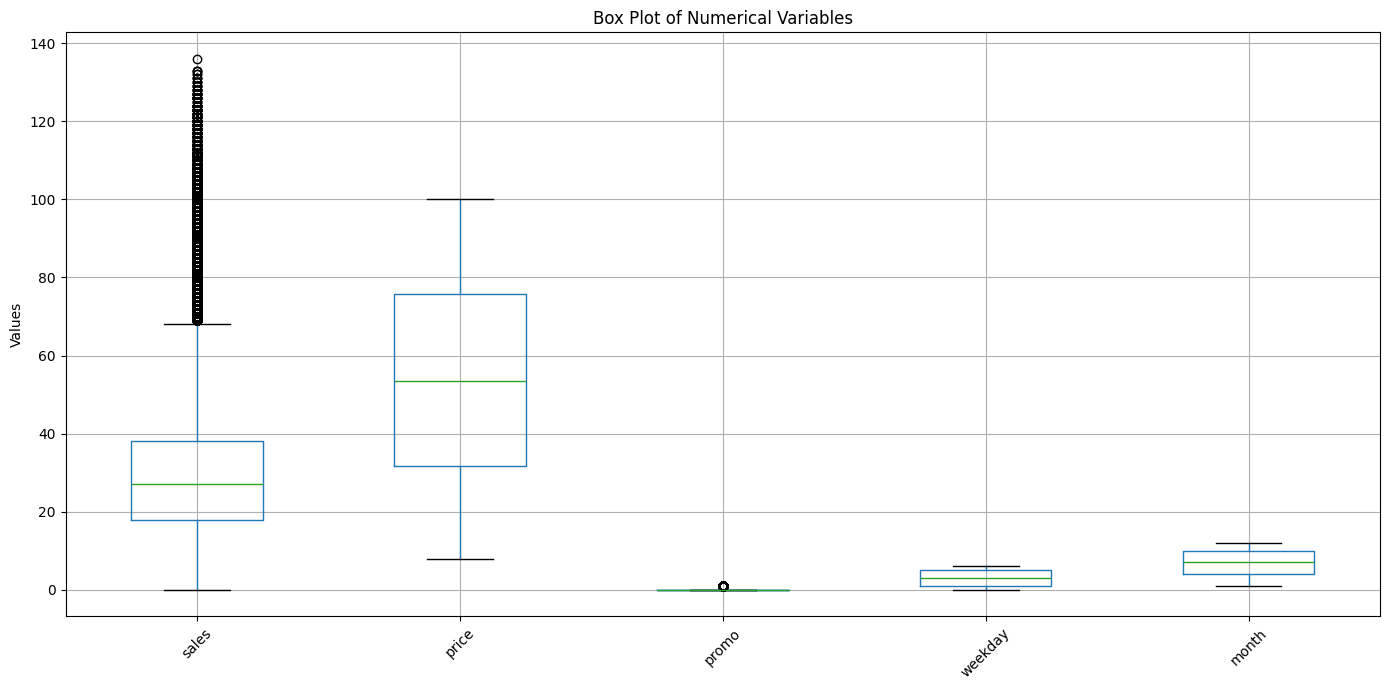

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

df[numerical_variables].boxplot()

plt.title("Box Plot of Numerical Variables")
plt.xticks(rotation=45)
plt.ylabel("Values")
plt.tight_layout()
plt.show()

D. Scatter plot

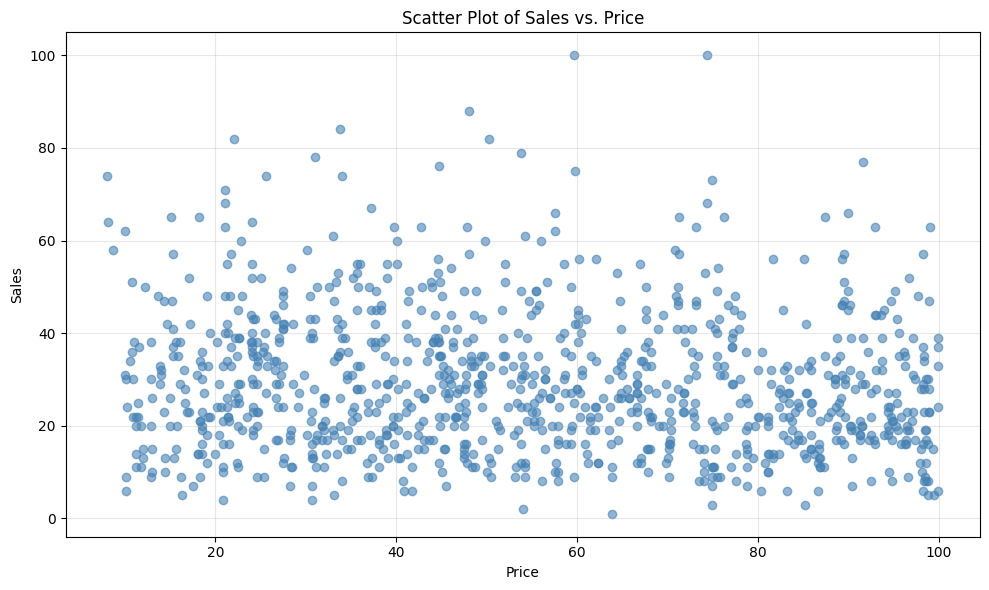

In [12]:
import matplotlib.pyplot as plt

# Sample 1,000 points for faster plotting of the large dataset
sample_df = df.sample(n=1000, random_state=42) if len(df) > 1000 else df

plt.figure(figsize=(10, 6))

plt.scatter(
    sample_df['price'],
    sample_df['sales'],
    alpha=0.6,
    color='steelblue'
)

plt.title("Scatter Plot of Sales vs. Price")
plt.xlabel("Price")
plt.ylabel("Sales")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

3. Data Pre-processing

A. Handle Missing Values

In [13]:
 # Check missing values
print(df.isnull().sum())

# Fill numerical missing values with median
for column in df.select_dtypes(include=np.number).columns:
    df[column] = df[column].fillna(df[column].median())

# Fill categorical missing values with mode
for column in df.select_dtypes(exclude=np.number).columns:
    df[column] = df[column].fillna(df[column].mode()[0])

print("\nMissing values after handling:")
print(df.isnull().sum())

date        0
store_id    1
item_id     1
sales       1
price       1
promo       1
weekday     1
month       1
dtype: int64

Missing values after handling:
date        0
store_id    0
item_id     0
sales       0
price       0
promo       0
weekday     0
month       0
dtype: int64


B. Remove Duplicate Records

In [14]:
print("Duplicates before removal:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after removal:", df.duplicated().sum())

Duplicates before removal: 0
Duplicates after removal: 0


D. Convert Categorical Variables into Numerical Form

In [15]:
# One-hot encode an available categorical column, for example, 'store_id'
df_encoded = pd.get_dummies(
    df,
    columns=["store_id"],
    drop_first=True
)

print(df_encoded.head())
print(df_encoded.shape)

         date item_id  sales  price  promo  weekday  month  store_id_store_10  \
0  2019-01-01  item_1   41.0  21.30    0.0      1.0    1.0              False   
1  2019-01-02  item_1   53.0  21.30    0.0      2.0    1.0              False   
2  2019-01-03  item_1   39.0  21.30    0.0      3.0    1.0              False   
3  2019-01-04  item_1   35.0  21.30    0.0      4.0    1.0              False   
4  2019-01-05  item_1   51.0  17.04    1.0      5.0    1.0              False   

   store_id_store_11  store_id_store_12  ...  store_id_store_17  \
0              False              False  ...              False   
1              False              False  ...              False   
2              False              False  ...              False   
3              False              False  ...              False   
4              False              False  ...              False   

   store_id_store_18  store_id_store_2  store_id_store_3  store_id_store_4  \
0              False            

4. Correlation Analysis

In [16]:
# Correlation matrix
correlation_matrix = df.select_dtypes(include=np.number).corr()

print("Correlation Matrix:")
print(correlation_matrix.round(4))

Correlation Matrix:
          sales   price   promo  weekday   month
sales    1.0000 -0.0852  0.2788  -0.2010 -0.2915
price   -0.0852  1.0000 -0.1282   0.0001 -0.0001
promo    0.2788 -0.1282  1.0000  -0.0010 -0.0004
weekday -0.2010  0.0001 -0.0010   1.0000 -0.0004
month   -0.2915 -0.0001 -0.0004  -0.0004  1.0000


5. Covariance Analysis

In [17]:
# Calculate covariance matrix
covariance_matrix = df.select_dtypes(include=np.number).cov()

print("Covariance Matrix:")
print(covariance_matrix.round(2))

Covariance Matrix:
          sales   price  promo  weekday  month
sales    232.62  -33.75   1.28    -6.13 -15.33
price    -33.75  674.48  -1.00     0.00  -0.01
promo      1.28   -1.00   0.09    -0.00  -0.00
weekday   -6.13    0.00  -0.00     4.00  -0.00
month    -15.33   -0.01  -0.00    -0.00  11.89


6. Train-Test Split

In [18]:
from sklearn.model_selection import train_test_split

# Prepare the feature matrix X and target y using the available sales dataset
# We'll drop non-numeric text columns and use 'sales' as our target variable
X = df_encoded.drop(columns=[
    "sales",
    "date",
    "item_id"
], errors="ignore")

y = df_encoded["sales"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data features shape:", X_train.shape)
print("Testing data features shape:", X_test.shape)

Training data features shape: (1266477, 21)
Testing data features shape: (316620, 21)


8. Ridge Regression

In [19]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

ridge.fit(X_train, y_train)

y_pred_ridge = ridge.predict(X_test)

mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression")
print("MAE :", mae_ridge)
print("RMSE:", rmse_ridge)
print("R2  :", r2_ridge)

Ridge Regression
MAE : 10.555773591820731
RMSE: 13.044212247300349
R2  : 0.2674083835817339


9. Lasso Regression

In [20]:
from sklearn.linear_model import Lasso

lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(alpha=1.0, max_iter=10000))
])

lasso.fit(X_train, y_train)

y_pred_lasso = lasso.predict(X_test)

mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
r2_lasso = r2_score(y_test, y_pred_lasso)

print("Lasso Regression")
print("MAE :", mae_lasso)
print("RMSE:", rmse_lasso)
print("R2  :", r2_lasso)

Lasso Regression
MAE : 10.893195987729852
RMSE: 13.563693053070606
R2  : 0.20789612639042732


10. Decision Tree

In [21]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(
    random_state=42
)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

mae_dt = mean_absolute_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))
r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree")
print("MAE :", mae_dt)
print("RMSE:", rmse_dt)
print("R2  :", r2_dt)

Decision Tree
MAE : 3.446223434896888
RMSE: 4.506989704513571
R2  : 0.9125420359955014


11. Random Forest

In [22]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest")
print("MAE :", mae_rf)
print("RMSE:", rmse_rf)
print("R2  :", r2_rf)

Random Forest
MAE : 3.4167510526364153
RMSE: 4.400718460677485
R2  : 0.9166177901025118


12. Model Selection

In [23]:
from sklearn.linear_model import LinearRegression

# Train Multiple Linear Regression model to define the missing metrics
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

# Compile results into a DataFrame
results = pd.DataFrame({
    "Model": [
        "Multiple Linear Regression",
        "Ridge Regression",
        "Lasso Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "MAE": [
        mae_lr,
        mae_ridge,
        mae_lasso,
        mae_dt,
        mae_rf
    ],

    "RMSE": [
        rmse_lr,
        rmse_ridge,
        rmse_lasso,
        rmse_dt,
        rmse_rf
    ],

    "R2 Score": [
        r2_lr,
        r2_ridge,
        r2_lasso,
        r2_dt,
        r2_rf
    ]
})

print(results.round(4))

                        Model      MAE     RMSE  R2 Score
0  Multiple Linear Regression  10.5558  13.0442    0.2674
1            Ridge Regression  10.5558  13.0442    0.2674
2            Lasso Regression  10.8932  13.5637    0.2079
3               Decision Tree   3.4462   4.5070    0.9125
4               Random Forest   3.4168   4.4007    0.9166


13. Save the Best Model Using Joblib

In [24]:
import joblib

# Automatically find the best model name based on the highest R2 Score from the results table
best_model_name = results.loc[results["R2 Score"].idxmax(), "Model"]
print(f"The best model based on R2 Score is: {best_model_name}")

# Map the best model name to the actual trained model variable
model_mapping = {
    "Multiple Linear Regression": lr,
    "Ridge Regression": ridge,
    "Lasso Regression": lasso,
    "Decision Tree": dt,
    "Random Forest": rf
}

best_model = model_mapping[best_model_name]

# Save the best model
joblib.dump(best_model, "best_model.pkl")
print("Best model saved successfully!")

The best model based on R2 Score is: Random Forest
Best model saved successfully!


In [25]:
import joblib

# Save the best model only. Random Forest is the best model and does not require a scaler,
# which is why no 'scaler' object is defined in your workspace.
joblib.dump(best_model, "best_model.pkl")
print("Best model (Random Forest) saved successfully!")

Best model (Random Forest) saved successfully!


In [26]:
from sklearn.preprocessing import OneHotEncoder
import joblib

# Updated to match the actual categorical columns in your dataset
categorical_columns = ["store_id", "item_id"]

encoder = OneHotEncoder(handle_unknown="ignore")

# Fit using the original dataframe 'df' matching the training indices where these columns still exist
encoder.fit(df.loc[X_train.index, categorical_columns])

joblib.dump(encoder, "encoder.pkl")

print("Encoder saved successfully!")

Encoder saved successfully!


In [27]:
joblib.dump(encoder, "encoder.pkl")


['encoder.pkl']